In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import ast
import gzip
import io
import time

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [67]:
df = pd.read_csv("listings.csv", low_memory=False)

In [69]:
print(f"Dataset shape: {df.shape}")
df.head(2)

Dataset shape: (500, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20260914164327,2026-09-16,NaN,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://a0.muscache.com/pictures/44627226/0e72...,4621559,...,4.56,3.22,3.67,NaN,NaN,1,1,0,0,0.06
1,3820211,https://www.airbnb.com/rooms/3820211,20260914164327,2026-09-16,NaN,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,19648678,...,4.81,4.81,4.78,NaN,NaN,7,7,0,0,2.17


In [70]:
print("Data Types:")
display(df.dtypes.value_counts())

print("\nDescriptive Statistics for Numerical Columns:")
display(df.describe())

Data Types:


float64    37
object     28
int64      25
Name: count, dtype: int64


Descriptive Statistics for Numerical Columns:


,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,5.000000e+02,5.000000e+02,0.0,5.000000e+02,5.000000e+02,0.0,500.00000,500.000000,500.000000,500.000000,...,449.000000,449.000000,449.000000,0.0,0.0,500.000000,500.00000,500.000000,500.000000,449.000000
mean,9.883705e+17,2.026091e+13,NaN,2.412574e+16,1.480443e+18,NaN,7.17600,4.966000,4.286000,5.268000,...,4.830423,4.643274,4.691693,NaN,NaN,7.420000,5.46400,1.944000,0.012000,1.753519
std,5.942214e+17,1.133947e-01,NaN,2.027301e+17,4.985197e+16,NaN,3.50451,3.491881,3.146427,3.503816,...,0.378165,0.436782,0.418326,NaN,NaN,7.911307,8.08303,3.866104,0.108994,1.878271
min,2.992450e+06,2.026091e+13,NaN,6.490680e+05,1.462518e+18,NaN,0.00000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,NaN,NaN,1.000000,0.00000,0.000000,0.000000,0.040000
25%,7.042966e+17,2.026091e+13,NaN,5.143576e+07,1.463574e+18,NaN,4.00000,2.000000,1.000000,2.000000,...,4.830000,4.500000,4.650000,NaN,NaN,2.000000,1.00000,0.000000,0.000000,0.350000
50%,1.120956e+18,2.026091e+13,NaN,2.117414e+08,1.468352e+18,NaN,8.00000,4.000000,4.000000,5.000000,...,4.960000,4.790000,4.810000,NaN,NaN,4.000000,2.00000,0.000000,0.000000,1.150000
75%,1.477201e+18,2.026091e+13,NaN,4.667901e+08,1.470110e+18,NaN,10.00000,8.000000,7.000000,8.000000,...,5.000000,4.930000,4.940000,NaN,NaN,11.000000,7.25000,2.000000,0.000000,2.510000
max,1.773591e+18,2.026091e+13,NaN,1.767798e+18,1.767798e+18,NaN,15.00000,11.000000,13.000000,11.000000,...,5.000000,5.000000,5.000000,NaN,NaN,31.000000,31.00000,15.000000,1.000000,10.540000


In [71]:
print("Top 10 Columns with Highest Missingness:")
display(df.isnull().mean().sort_values(ascending=False).head(10))

Top 10 Columns with Highest Missingness:


neighborhood_overview        1.0
host_since                   1.0
host_response_time           1.0
host_thumbnail_url           1.0
host_acceptance_rate         1.0
host_response_rate           1.0
host_verifications           1.0
neighbourhood                1.0
host_total_listings_count    1.0
host_neighbourhood           1.0
dtype: float64

In [72]:
if 'id' in df.columns:
    ids = df['id'].dropna()
    duplicate_ids = ids[ids.duplicated(keep=False)]

    print(f"Total rows: {len(df)}")
    print(f"Missing IDs: {df['id'].isna().sum()}")
    print(f"Duplicate ID rows: {ids.duplicated().sum()}")
    print(f"Unique IDs involved in duplicates: {duplicate_ids.nunique()}")
else:
    print("Warning: 'id' column not found.")

Total rows: 500
Missing IDs: 0
Duplicate ID rows: 0
Unique IDs involved in duplicates: 0


In [73]:
fully_missing = df.columns[df.isna().all()]

print(f"Fully missing columns: {len(fully_missing)}")
print(fully_missing)

Fully missing columns: 15
Index(['neighborhood_overview', 'host_since', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url',
       'host_neighbourhood', 'host_total_listings_count', 'host_verifications',
       'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms',
       'calendar_updated', 'license', 'instant_bookable'],
      dtype='object')


In [74]:
low_cardinality = df.nunique().loc[lambda s: s.between(1, 3)].index

if len(low_cardinality):
    low_cardinality_summary = pd.DataFrame({
        'Data Type': df[low_cardinality].dtypes.astype(str),
        'Unique Values': df[low_cardinality].nunique(),
        'Value Counts': {
            col: df[col].value_counts(dropna=False).to_dict()
            for col in low_cardinality
        }
    })
    display(low_cardinality_summary)
else:
    print("No columns with 1–3 unique non-missing values.")

,Data Type,Unique Values,Value Counts
scrape_id,int64,1,{20260914164327: 500}
last_scraped,object,1,{'2026-09-16': 500}
source,object,1,"{nan: 465, 'previous scrape': 35}"
host_is_superhost,object,2,"{'f': 273, 't': 227}"
host_has_profile_pic,object,2,"{'t': 473, 'f': 27}"
host_identity_verified,object,2,"{'t': 498, 'f': 2}"
room_type,object,3,"{'Entire home/apt': 352, 'Private room': 147, ..."
has_availability,object,1,"{'t': 497, nan: 3}"
calendar_last_scraped,object,1,{'2026-09-16': 500}
calculated_host_listings_count_shared_rooms,int64,2,"{0: 494, 1: 6}"


In [75]:
if 'price' in df.columns:
    print(f"Price data type: {df['price'].dtype}")
    print(df['price'].dropna().head(5).tolist())

Price data type: object
['$65.73', '$171.00', '$242.00', '$79.00', '$50.00']


Missing or invalid prices: 33
Zero or negative prices: 0


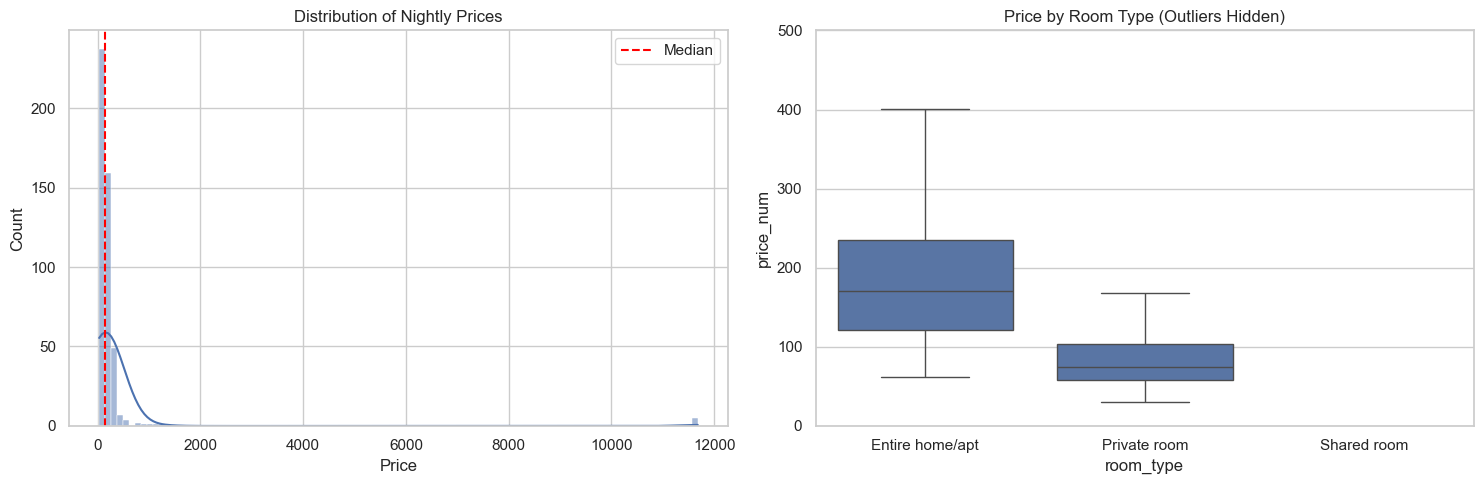

Price Skewness: 9.37
Log Price Skewness: 2.10


In [76]:
if 'price' not in df.columns:
    raise KeyError("The dataset does not contain a 'price' column.")

price = pd.to_numeric(
    df['price'].astype('string').str.replace(r'[$,]', '', regex=True),
    errors='coerce'
)
if 'price_quote_price_per_night' in df.columns:
    alternative_price = pd.to_numeric(
        df['price_quote_price_per_night'],
        errors='coerce'
    )

    price = alternative_price.combine_first(price)

df['price_num'] = price

print("Missing or invalid prices:", df['price_num'].isna().sum())
print("Zero or negative prices:", (df['price_num'].dropna() <= 0).sum())

valid_prices = df.loc[df['price_num'] > 0, 'price_num'].dropna()

if valid_prices.empty:
    raise ValueError("No valid positive prices are available for analysis.")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(valid_prices, bins=100, kde=True, ax=axes[0])
axes[0].axvline(
    valid_prices.median(),
    color='red',
    linestyle='--',
    label='Median'
)
axes[0].set_title('Distribution of Nightly Prices')
axes[0].set_xlabel('Price')
axes[0].legend()

if 'room_type' in df.columns:
    plot_data = df.loc[
        df['price_num'] > 0,
        ['room_type', 'price_num']
    ].dropna()

    sns.boxplot(
        x='room_type',
        y='price_num',
        data=plot_data,
        showfliers=False,
        ax=axes[1]
    )
    axes[1].set_title('Price by Room Type (Outliers Hidden)')
    axes[1].set_ylim(0, 500)
else:
    axes[1].set_visible(False)
    print("Warning: 'room_type' column is missing.")

plt.tight_layout()
plt.show()

print(f"Price Skewness: {valid_prices.skew():.2f}")
print(f"Log Price Skewness: {np.log1p(valid_prices).skew():.2f}")

,Count,Percentage
superhost_binary,,
0.0,273,54.6
1.0,227,45.4



Missing or invalid labels: 0


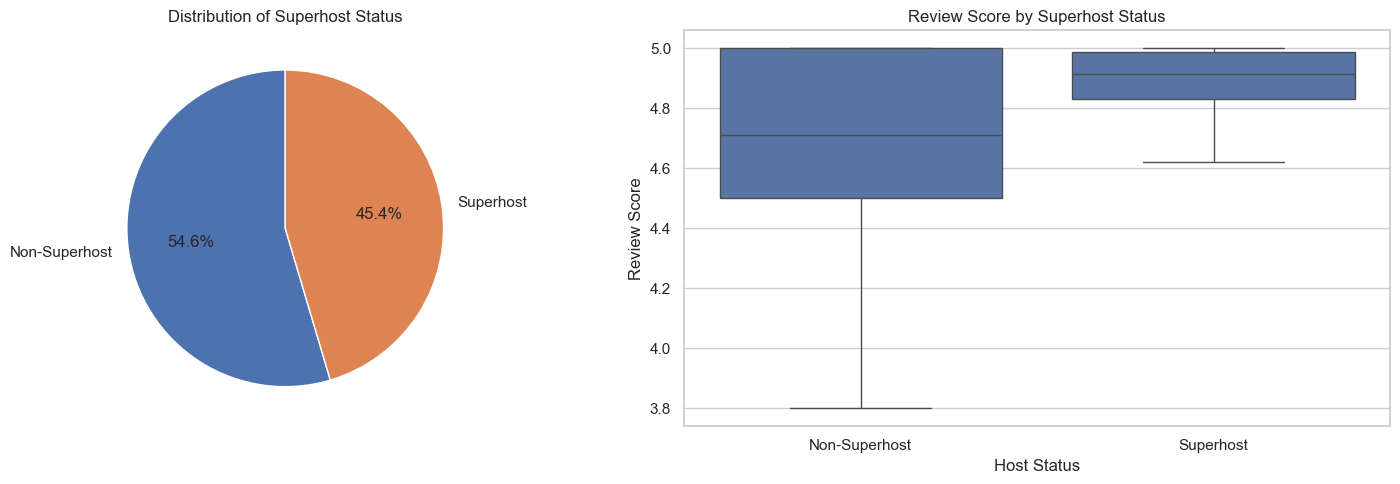

In [77]:
if 'host_is_superhost' not in df.columns:
    raise KeyError("Column 'host_is_superhost' is missing.")

status = df['host_is_superhost']

if status.dtype == 'object' or isinstance(status.dtype, pd.StringDtype):
    status = status.astype('string').str.strip().str.lower()

    df['superhost_binary'] = status.map({
        't': 1,
        'f': 0,
        'true': 1,
        'false': 0,
        '1': 1,
        '0': 0
    })
else:
    df['superhost_binary'] = pd.to_numeric(status, errors='coerce')

df.loc[
    ~df['superhost_binary'].isin([0, 1]),
    'superhost_binary'
] = np.nan

class_counts = df['superhost_binary'].value_counts().sort_index()
class_percentages = class_counts.div(class_counts.sum()).mul(100).round(2)

display(pd.DataFrame({
    'Count': class_counts,
    'Percentage': class_percentages
}))

print(f"\nMissing or invalid labels: {df['superhost_binary'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.rename({
    0: 'Non-Superhost',
    1: 'Superhost'
}).plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    ax=axes[0]
)

axes[0].set_ylabel('')
axes[0].set_title('Distribution of Superhost Status')


if 'review_scores_rating' in df.columns:
    plot_data = df[
        ['superhost_binary', 'review_scores_rating']
    ].copy()

    plot_data['review_scores_rating'] = pd.to_numeric(
        plot_data['review_scores_rating'],
        errors='coerce'
    )

    plot_data = plot_data.dropna()

    sns.boxplot(
        x='superhost_binary',
        y='review_scores_rating',
        data=plot_data,
        showfliers=False,
        ax=axes[1]
    )

    axes[1].set_title('Review Score by Superhost Status')
    axes[1].set_xlabel('Host Status')
    axes[1].set_ylabel('Review Score')
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(['Non-Superhost', 'Superhost'])
else:
    axes[1].set_visible(False)
    print("\nWarning: 'review_scores_rating' column is missing.")

plt.tight_layout()
plt.show()

In [78]:
prices = df.loc[
    df['price_num'].notna() & (df['price_num'] > 0),
    'price_num'
]

if prices.empty:
    raise ValueError("No valid positive prices available for outlier analysis.")

Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)
IQR = Q3 - Q1

lower_bound_iqr = Q1 - 1.5 * IQR
upper_bound_iqr = Q3 + 1.5 * IQR

iqr_outliers = (prices < lower_bound_iqr) | (prices > upper_bound_iqr)

print("IQR Method")
print(f"Lower bound: ${lower_bound_iqr:.2f}")
print(f"Upper bound: ${upper_bound_iqr:.2f}")
print(f"Potential outliers: {iqr_outliers.sum()}")


std = prices.std()

if std > 0:
    z_scores = ((prices - prices.mean()) / std).abs()
    z_outliers = z_scores > 3

    print("\nZ-Score Method")
    print(f"Potential outliers (|Z| > 3): {z_outliers.sum()}")
else:
    print("\nZ-Score cannot identify outliers because price variance is zero.")


iso_forest = IsolationForest(
    contamination=0.05,
    random_state=RANDOM_STATE
)

iso_predictions = iso_forest.fit_predict(prices.to_frame())

iso_outlier_count = (iso_predictions == -1).sum()

print("\nIsolation Forest")
print(f"Outliers detected: {iso_outlier_count}")
print(f"Contamination setting: 5%")


columns_to_show = [
    col for col in ['id', 'name', 'price_num', 'room_type']
    if col in df.columns
]

print("\nTop 5 Most Expensive Listings:")

print(
    df.loc[prices.index, columns_to_show]
      .sort_values('price_num', ascending=False)
      .head(5)
      .to_string(index=False)
)

IQR Method
Lower bound: $-90.71
Upper bound: $389.03
Potential outliers: 20

Z-Score Method
Potential outliers (|Z| > 3): 5

Isolation Forest
Outliers detected: 24
Contamination setting: 5%

Top 5 Most Expensive Listings:
                 id                                  name  price_num       room_type
1511463115578002586             Large 1 bedroom downtown!    11680.0 Entire home/apt
1511560319275262460            Spacious Studio | Downtown    11680.0 Entire home/apt
1511453437878117120 Large Studio Downtown with Pool Table    11680.0 Entire home/apt
1511573692636646423      Very Comfortable Studio Downtown    11680.0 Entire home/apt
1511475748634247539 Spacious Downtown 1BR Cozy Apartment!    11680.0 Entire home/apt


In [79]:
columns_to_drop = fully_missing + ['price']
df = df.drop(columns=columns_to_drop, errors='ignore')

required_targets = ['price_num', 'superhost_binary']
missing_targets = [col for col in required_targets if col not in df.columns]

if missing_targets:
    raise KeyError(f"Missing target columns: {missing_targets}")

invalid_price_mask = df['price_num'].isna() | (df['price_num'] <= 10) | (df['price_num'] >= 5000)

print(f"Rows with missing or out-of-range prices: {invalid_price_mask.sum()}")
print(f"Rows with missing Superhost labels: {df['superhost_binary'].isna().sum()}")

def count_amenities(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (list, tuple)):
        return len(value)

    if isinstance(value, str):
        value = value.strip()

        if not value:
            return np.nan

        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, (list, tuple)):
                return len(parsed)

        except (ValueError, SyntaxError):
            pass

    return np.nan

if 'amenities' in df.columns:
    df['num_amenities'] = df['amenities'].apply(count_amenities)

    print(
        "Missing amenity counts:",
        df['num_amenities'].isna().sum()
    )
else:
    print("Warning: 'amenities' column is not available.")

key_features = [
    col for col in ['review_scores_rating', 'bedrooms']
    if col in df.columns
]

if key_features:
    print("\nMissing-value percentages in key features:")
    display(df[key_features].isna().mean().mul(100).round(2))
else:
    print("\nNo requested key features were found.")

Rows with missing or out-of-range prices: 38
Rows with missing Superhost labels: 0
Missing amenity counts: 0

Missing-value percentages in key features:


review_scores_rating    10.2
bedrooms                 0.0
dtype: float64

In [80]:
def group_property(value):
    value = str(value).lower()

    if 'house' in value:
        return 'House'
    if 'apartment' in value or 'flat' in value:
        return 'Apartment'
    return 'Other'

if 'property_type' in df:
    df['property_group'] = df['property_type'].apply(group_property)

if 'availability_30' in df:
    df['availability_ratio_30'] = df['availability_30'] / 30

drop_cols = [
    'id', 'listing_url', 'scrape_id', 'name', 'description',
    'host_name', 'neighborhood_overview', 'picture_url', 'amenities'
]

df.drop(columns=drop_cols, errors='ignore', inplace=True)

new_features = [
    col for col in ['property_group', 'availability_ratio_30', 'num_amenities']
    if col in df.columns
]

display(df[new_features].head())

,property_group,availability_ratio_30,num_amenities
0,Other,0.000000,8
1,Other,0.766667,32
2,Other,0.066667,43
3,Other,0.433333,28
4,Other,0.300000,23


In [81]:
num_features = [
    'accommodates',
    'bedrooms',
    'beds',
    'review_scores_rating',
    'number_of_reviews',
    'num_amenities',
    'availability_30',
    'availability_ratio_30',
    'minimum_nights'
]

cat_features = [
    'room_type',
    'property_type',
    'property_group',
    'neighbourhood_cleansed'
]

leakage_candidates = [
    c for c in df.columns
    if any(term in c.lower() for term in ['price', 'superhost', 'revenue'])
]

print("Potential leakage columns:")
print(leakage_candidates)

excluded_columns = set(leakage_candidates)

num_features = [
    c for c in num_features
    if c in df.columns and c not in excluded_columns
]

cat_features = [
    c for c in cat_features
    if c in df.columns and c not in excluded_columns
]

requested_features = [
    'accommodates', 'bedrooms', 'beds', 'review_scores_rating',
    'number_of_reviews', 'num_amenities', 'availability_30',
    'availability_ratio_30', 'minimum_nights', 'room_type',
    'property_type', 'property_group', 'neighbourhood_cleansed'
]

missing_features = [
    c for c in requested_features
    if c not in df.columns
]

print("\nRequested features missing from dataset:")
print(missing_features)

selected_features = num_features + cat_features

X_reg = df[selected_features].copy()
X_clf = df[selected_features].copy()

print(f"\nNumerical features selected: {len(num_features)}")
print(f"Categorical features selected: {len(cat_features)}")
print(f"Total features selected: {len(selected_features)}")

Potential leakage columns:
['host_is_superhost', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'estimated_revenue_l365d', 'price_num', 'superhost_binary']

Requested features missing from dataset:
[]

Numerical features selected: 9
Categorical features selected: 4
Total features selected: 13


In [82]:
cat_unique = X_clf[cat_features].nunique(dropna=True)

print("Categorical feature cardinality:")
display(cat_unique.sort_values(ascending=False))

Categorical feature cardinality:


property_type             21
neighbourhood_cleansed    15
room_type                  3
property_group             3
dtype: int64

In [83]:
df_price = df[
    df['price_num'].notna()
    & np.isfinite(df['price_num'])
    & (df['price_num'] > 0)
].copy()

X_reg = df_price[num_features + cat_features].copy()
y_reg = np.log1p(df_price['price_num'])

df_superhost = df[df['superhost_binary'].isin([0, 1])].copy()

X_clf = df_superhost[num_features + cat_features].copy()
y_clf = df_superhost['superhost_binary'].astype(int)

In [84]:
X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE
)

X_train_clf, X_val_clf, y_train_clf, y_val_clf = train_test_split(
    X_clf, y_clf,
    test_size=0.2,
    stratify=y_clf,
    random_state=RANDOM_STATE
)

print("Regression:", X_train_reg.shape, X_val_reg.shape)
print("Classification:", X_train_clf.shape, X_val_clf.shape)

print(f"Train Superhost ratio: {y_train_clf.mean():.3f}")
print(f"Validation Superhost ratio: {y_val_clf.mean():.3f}")

Regression: (373, 13) (94, 13)
Classification: (400, 13) (100, 13)
Train Superhost ratio: 0.455
Validation Superhost ratio: 0.450


In [85]:
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

In [86]:
dummy_reg_pipe = Pipeline([
    ('pre', preprocessor),
    ('model', DummyRegressor(strategy='median'))
])

dummy_reg_pipe.fit(X_train_reg, y_train_reg)

dummy_reg_preds = np.expm1(dummy_reg_pipe.predict(X_val_reg))
y_val_reg_original = np.expm1(y_val_reg)

dummy_mae = mean_absolute_error(
    y_val_reg_original,
    dummy_reg_preds
)

dummy_clf_pipe = Pipeline([
    ('pre', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])

dummy_clf_pipe.fit(X_train_clf, y_train_clf)

dummy_clf_preds = dummy_clf_pipe.predict(X_val_clf)

dummy_f1 = f1_score(
    y_val_clf,
    dummy_clf_preds,
    zero_division=0
)

dummy_recall = recall_score(
    y_val_clf,
    dummy_clf_preds,
    zero_division=0
)

print(f"Baseline Regression MAE: ${dummy_mae:.2f}")
print(f"Baseline Classification F1: {dummy_f1:.3f}")
print(f"Baseline Classification Recall: {dummy_recall:.3f}")

Baseline Regression MAE: $201.70
Baseline Classification F1: 0.000
Baseline Classification Recall: 0.000


In [87]:
clf_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

results_clf = []
for name, model in clf_models.items():

    pipe = Pipeline([
        ('pre', clone(preprocessor)),
        ('model', model)
    ])

    start = time.time()
    pipe.fit(X_train_clf, y_train_clf)
    train_time = time.time() - start

    preds = pipe.predict(X_val_clf)

    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_val_clf, preds),
        'Precision': precision_score(
            y_val_clf, preds, zero_division=0
        ),
        'Recall': recall_score(
            y_val_clf, preds, zero_division=0
        ),
        'F1-Score': f1_score(
            y_val_clf, preds, zero_division=0
        ),
        'Macro-F1': f1_score(
            y_val_clf, preds,
            average='macro',
            zero_division=0
        ),
        'Train Time (s)': round(train_time, 2)
    }

    if hasattr(pipe, 'predict_proba'):
        scores = pipe.predict_proba(X_val_clf)[:, 1]
    elif hasattr(pipe, 'decision_function'):
        scores = pipe.decision_function(X_val_clf)
    else:
        scores = None

    if scores is not None:
        metrics['ROC-AUC'] = roc_auc_score(
            y_val_clf, scores
        )

    results_clf.append(metrics)


SVC_SAMPLE_SIZE = min(5000, len(X_train_clf))

rng = np.random.default_rng(RANDOM_STATE)

sample_pos = rng.choice(
    len(X_train_clf),
    size=SVC_SAMPLE_SIZE,
    replace=False
)

X_train_sample = X_train_clf.iloc[sample_pos]
y_train_sample = (
    y_train_clf.iloc[sample_pos]
    if hasattr(y_train_clf, 'iloc')
    else y_train_clf[sample_pos]
)

svc_pipe = Pipeline([
    ('pre', clone(preprocessor)),
    ('model', SVC(
        kernel='rbf',
        probability=False,
        random_state=RANDOM_STATE
    ))
])

start = time.time()
svc_pipe.fit(X_train_sample, y_train_sample)
svc_train_time = time.time() - start

svc_preds = svc_pipe.predict(X_val_clf)
svc_scores = svc_pipe.decision_function(X_val_clf)

results_clf.append({
    'Model': 'SVC (RBF, sampled)',
    'Accuracy': accuracy_score(y_val_clf, svc_preds),
    'Precision': precision_score(
        y_val_clf, svc_preds, zero_division=0
    ),
    'Recall': recall_score(
        y_val_clf, svc_preds, zero_division=0
    ),
    'F1-Score': f1_score(
        y_val_clf, svc_preds, zero_division=0
    ),
    'Macro-F1': f1_score(
        y_val_clf, svc_preds,
        average='macro',
        zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_val_clf, svc_scores),
    'Train Time (s)': round(svc_train_time, 2)
})
results_clf_df = pd.DataFrame(results_clf)

display(
    results_clf_df.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True).round(3)
)

,Model,Accuracy,Precision,Recall,F1-Score,Macro-F1,Train Time (s),ROC-AUC
0,Random Forest,0.84,0.837,0.800,0.818,0.838,0.16,0.948
1,Logistic Regression,0.82,0.800,0.800,0.800,0.818,0.02,0.859
2,"SVC (RBF, sampled)",0.82,0.800,0.800,0.800,0.818,0.02,0.924
3,Decision Tree,0.76,0.756,0.689,0.721,0.755,0.01,0.754


In [88]:
reg_models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

results_reg = []
actuals = np.expm1(np.asarray(y_val_reg))

for name, model in reg_models.items():

    pipe = Pipeline([
        ('pre', clone(preprocessor)),
        ('model', model)
    ])

    start = time.time()
    pipe.fit(X_train_reg, y_train_reg)
    train_time = time.time() - start

    start = time.time()
    pred_log = pipe.predict(X_val_reg)
    predict_time = time.time() - start

    preds = np.maximum(np.expm1(pred_log), 0)

    results_reg.append({
        'Model': name,
        'MAE': mean_absolute_error(actuals, preds),
        'RMSE': np.sqrt(
            mean_squared_error(actuals, preds)
        ),
        'R2': r2_score(actuals, preds),
        'Train Time (s)': round(train_time, 2),
        'Predict Time (s)': round(predict_time, 2)
    })

KRR_SAMPLE_SIZE = min(2000, len(X_train_reg))

rng = np.random.default_rng(RANDOM_STATE)

sample_pos_reg = rng.choice(
    len(X_train_reg),
    size=KRR_SAMPLE_SIZE,
    replace=False
)

X_train_reg_sample = X_train_reg.iloc[sample_pos_reg]

y_train_reg_sample = (
    y_train_reg.iloc[sample_pos_reg]
    if hasattr(y_train_reg, 'iloc')
    else y_train_reg[sample_pos_reg]
)

kr_pipe = Pipeline([
    ('pre', clone(preprocessor)),
    ('model', KernelRidge(
        kernel='rbf',
        alpha=1.0
    ))
])

start = time.time()
kr_pipe.fit(X_train_reg_sample, y_train_reg_sample)
krr_train_time = time.time() - start

batch_size = 1000
krr_pred_log = []

start = time.time()

for i in range(0, len(X_val_reg), batch_size):
    X_batch = X_val_reg.iloc[i:i + batch_size]
    batch_preds = kr_pipe.predict(X_batch)
    krr_pred_log.extend(batch_preds)

krr_predict_time = time.time() - start

krr_preds = np.maximum(
    np.expm1(np.asarray(krr_pred_log)),
    0
)

results_reg.append({
    'Model': 'Kernel Ridge (RBF, sampled)',
    'MAE': mean_absolute_error(actuals, krr_preds),
    'RMSE': np.sqrt(
        mean_squared_error(actuals, krr_preds)
    ),
    'R2': r2_score(actuals, krr_preds),
    'Train Time (s)': round(krr_train_time, 2),
    'Predict Time (s)': round(krr_predict_time, 2)
})

results_reg_df = pd.DataFrame(results_reg)

display(
    results_reg_df.sort_values(
        by='MAE',
        ascending=True
    ).reset_index(drop=True).round(3)
)

,Model,MAE,RMSE,R2,Train Time (s),Predict Time (s)
0,Ridge,162.221,1174.461,0.020,0.01,0.01
1,Linear Regression,164.272,1173.694,0.021,0.01,0.01
2,"Kernel Ridge (RBF, sampled)",167.836,1181.278,0.009,0.02,0.01
3,Random Forest,231.826,1255.034,-0.119,0.15,0.03
4,Decision Tree,287.462,1674.800,-0.993,0.01,0.01


In [89]:
df_reg_results = pd.DataFrame(results_reg)
df_clf_results = pd.DataFrame(results_clf)

for col in ['MAE', 'RMSE', 'R2']:
    if col in df_reg_results.columns:
        df_reg_results[col] = pd.to_numeric(
            df_reg_results[col], errors='coerce'
        )

for col in ['F1-Score', 'Accuracy', 'Precision', 'Recall', 'ROC-AUC']:
    if col in df_clf_results.columns:
        df_clf_results[col] = pd.to_numeric(
            df_clf_results[col], errors='coerce'
        )

if 'MAE' in df_reg_results.columns:
    df_reg_results = df_reg_results.sort_values(
        'MAE', ascending=True
    )

if 'F1-Score' in df_clf_results.columns:
    df_clf_results = df_clf_results.sort_values(
        'F1-Score', ascending=False
    )

print("Regression Summary (Lower MAE is Better)")
display(df_reg_results.round(3))

print("\nClassification Summary (Higher F1 is Better)")
display(df_clf_results.round(3))

Regression Summary (Lower MAE is Better)


,Model,MAE,RMSE,R2,Train Time (s),Predict Time (s)
1,Ridge,162.221,1174.461,0.020,0.01,0.01
0,Linear Regression,164.272,1173.694,0.021,0.01,0.01
4,"Kernel Ridge (RBF, sampled)",167.836,1181.278,0.009,0.02,0.01
3,Random Forest,231.826,1255.034,-0.119,0.15,0.03
2,Decision Tree,287.462,1674.800,-0.993,0.01,0.01



Classification Summary (Higher F1 is Better)


,Model,Accuracy,Precision,Recall,F1-Score,Macro-F1,Train Time (s),ROC-AUC
2,Random Forest,0.84,0.837,0.800,0.818,0.838,0.16,0.948
0,Logistic Regression,0.82,0.800,0.800,0.800,0.818,0.02,0.859
3,"SVC (RBF, sampled)",0.82,0.800,0.800,0.800,0.818,0.02,0.924
1,Decision Tree,0.76,0.756,0.689,0.721,0.755,0.01,0.754


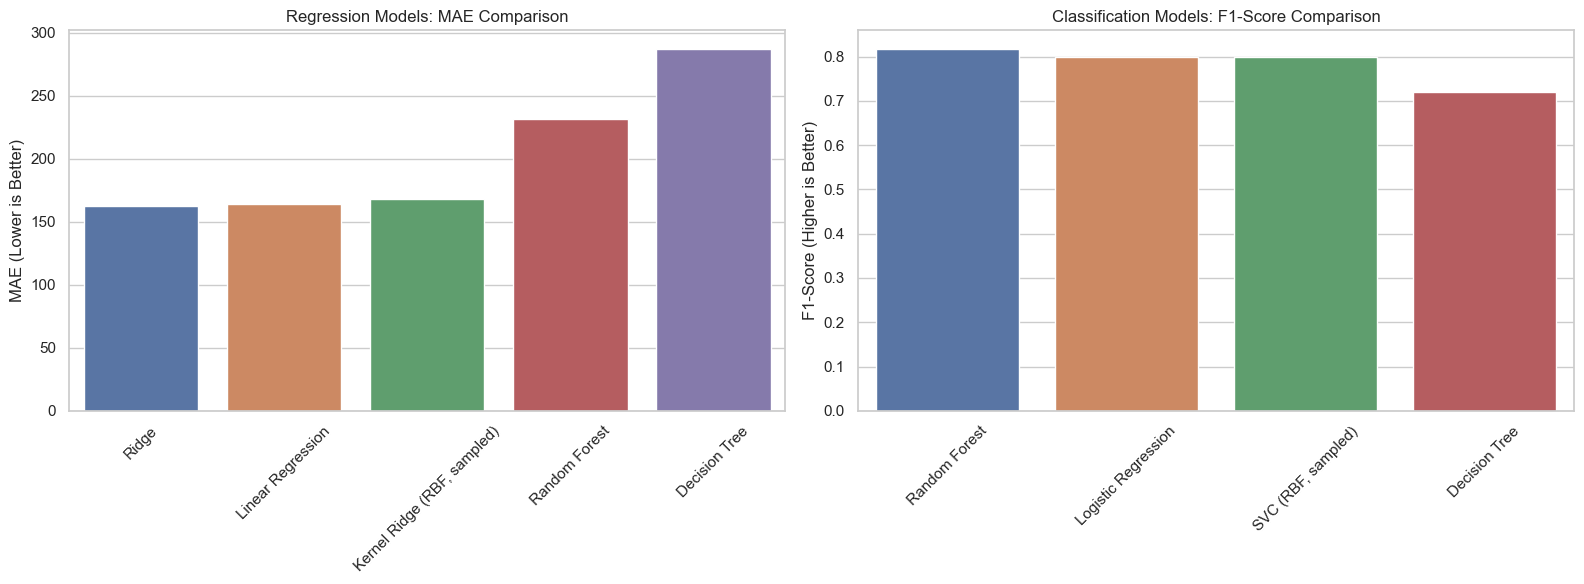

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=df_reg_results,
    x='Model',
    y='MAE',
    hue='Model',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Regression Models: MAE Comparison')
axes[0].set_xlabel('')
axes[0].set_ylabel('MAE (Lower is Better)')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=df_clf_results,
    x='Model',
    y='F1-Score',
    hue='Model',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Classification Models: F1-Score Comparison')
axes[1].set_xlabel('')
axes[1].set_ylabel('F1-Score (Higher is Better)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [91]:
best_reg_pipe = Pipeline([
    ('pre', clone(preprocessor)),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

best_reg_pipe.fit(X_train_reg, y_train_reg)

reg_preds = np.maximum(
    np.expm1(best_reg_pipe.predict(X_val_reg)),
    0
)

reg_actuals = np.expm1(np.asarray(y_val_reg))

df_errors = pd.DataFrame({
    'Actual': reg_actuals,
    'Predicted': reg_preds,
    'Abs_Error': np.abs(reg_actuals - reg_preds),
    'Signed_Error': reg_preds - reg_actuals
}, index=X_val_reg.index)

df_errors = pd.concat(
    [df_errors, X_val_reg],
    axis=1
)

print("Top 10 Worst Regression Predictions (by absolute error):")

display(
    df_errors
    .sort_values('Abs_Error', ascending=False)
    .head(10)
)

print(
    f"\nValidation MAE: "
    f"${mean_absolute_error(reg_actuals, reg_preds):.2f}"
)

Top 10 Worst Regression Predictions (by absolute error):


,Actual,Predicted,Abs_Error,Signed_Error,accommodates,bedrooms,beds,review_scores_rating,number_of_reviews,num_amenities,availability_30,availability_ratio_30,minimum_nights,room_type,property_type,property_group,neighbourhood_cleansed
387,11680.00,1216.182657,10463.817343,-10463.817343,3,1,1.0,NaN,0,40,30,1.000000,2.0,Entire home/apt,Entire home,Other,SIXTH WARD
495,197.00,6172.425307,5975.425307,5975.425307,3,1,2.0,NaN,0,47,30,1.000000,1.0,Entire home/apt,Entire rental unit,Other,SECOND WARD
31,157.50,1582.471531,1424.971531,1424.971531,2,1,1.0,NaN,0,50,29,0.966667,2.0,Entire home/apt,Entire rental unit,Other,SIXTH WARD
457,227.00,892.025800,665.025800,665.025800,4,1,2.0,5.00,3,47,30,1.000000,1.0,Entire home/apt,Entire rental unit,Other,FOURTEENTH WARD
93,818.00,363.943549,454.056451,-454.056451,12,5,7.0,4.92,122,55,26,0.866667,2.0,Entire home/apt,Entire home,Other,TENTH WARD
15,432.50,267.359350,165.140650,-165.140650,6,2,3.0,4.97,58,84,23,0.766667,2.0,Entire home/apt,Entire home,Other,FIFTEENTH WARD
401,72.00,228.809399,156.809399,156.809399,2,2,2.0,NaN,0,13,27,0.900000,1.0,Entire home/apt,Entire rental unit,Other,FIRST WARD
131,401.00,282.045653,118.954347,-118.954347,6,4,4.0,4.53,49,49,30,1.000000,1.0,Entire home/apt,Entire rental unit,Other,TENTH WARD
421,115.00,230.081549,115.081549,115.081549,6,1,4.0,4.67,6,67,0,0.000000,1.0,Entire home/apt,Entire townhouse,House,SECOND WARD
435,338.68,223.805938,114.874062,-114.874062,6,3,3.0,4.58,12,20,6,0.200000,1.0,Entire home/apt,Entire rental unit,Other,SEVENTH WARD



Validation MAE: $231.83


In [92]:
best_clf_pipe = Pipeline([
    ('pre', clone(preprocessor)),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

best_clf_pipe.fit(X_train_clf, y_train_clf)

clf_preds = best_clf_pipe.predict(X_val_clf)

y_val_clf_array = np.asarray(y_val_clf)

incorrect = y_val_clf_array != clf_preds

df_clf_errors = pd.DataFrame({
    'Actual': y_val_clf_array[incorrect],
    'Predicted': clf_preds[incorrect]
}, index=X_val_clf.index[incorrect])

df_clf_errors = pd.concat(
    [df_clf_errors, X_val_clf.loc[df_clf_errors.index]],
    axis=1
)

print("Incorrect Classification Predictions:")

display(df_clf_errors.head(10))

print(f"\nTotal incorrect predictions: {incorrect.sum()}")

Incorrect Classification Predictions:


,Actual,Predicted,accommodates,bedrooms,beds,review_scores_rating,number_of_reviews,num_amenities,availability_30,availability_ratio_30,minimum_nights,room_type,property_type,property_group,neighbourhood_cleansed
372,1,0,1,1,1.0,5.00,3,44,27,0.900000,21.0,Private room,Private room in home,Other,TENTH WARD
36,0,1,5,1,2.0,4.79,766,55,28,0.933333,1.0,Entire home/apt,Entire loft,Other,SECOND WARD
115,0,1,5,3,3.0,4.97,103,53,0,0.000000,30.0,Entire home/apt,Entire rental unit,Other,SIXTH WARD
141,0,1,1,1,1.0,4.70,64,13,24,0.800000,1.0,Private room,Private room in home,Other,FOURTEENTH WARD
117,1,0,2,0,1.0,4.75,8,19,0,0.000000,14.0,Entire home/apt,Entire rental unit,Other,SECOND WARD
49,0,1,4,2,2.0,4.74,58,35,23,0.766667,1.0,Entire home/apt,Entire rental unit,Other,SIXTH WARD
305,1,0,4,2,2.0,NaN,0,10,0,0.000000,13.0,Entire home/apt,Entire rental unit,Other,EIGHTH WARD
382,1,0,2,1,1.0,4.77,26,23,17,0.566667,2.0,Private room,Private room in rental unit,Other,SIXTH WARD
496,1,0,7,2,3.0,NaN,0,57,23,0.766667,1.0,Entire home/apt,Entire rental unit,Other,THIRD WARD
136,0,1,2,1,1.0,5.00,15,42,0,0.000000,7.0,Entire home/apt,Entire rental unit,Other,SIXTH WARD



Total incorrect predictions: 16


In [93]:
fitted_preprocessor = best_reg_pipe.named_steps['pre']
rf_model = best_reg_pipe.named_steps['model']

feature_names = fitted_preprocessor.get_feature_names_out()

feature_imp = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Top 10 Most Important Features for Price Prediction:")

display(feature_imp.head(10).to_frame(name='Importance'))

Top 10 Most Important Features for Price Prediction:


,Importance
cat__room_type_Private room,0.211159
num__number_of_reviews,0.146236
num__num_amenities,0.112590
num__accommodates,0.096271
num__minimum_nights,0.086793
num__availability_ratio_30,0.068038
num__availability_30,0.046778
num__bedrooms,0.040239
cat__room_type_Entire home/apt,0.035160
num__review_scores_rating,0.034875
